Estimate a shared set of CMR parameters from participants' recorded recalls in the war-photo-recall experiment. Save the fit, generate simulated recalls and compare the model's behavior with the observations. The simulation and parameter-exploration templates build on the result of this procedure.

## Parameters and setup

The tagged **parameters** cell defines one run. Its defaults reproduce the worked example:
all list conditions, a pooled CMR fit, nine free parameters and ten simulations per list.
`parameters["fixed"]` supplies the other model values; `parameters["free"]` names the estimated
values and their bounds. The model, objective, simulator and optimizer are import paths,
resolved in later cells after Quarto or Papermill supplies any replacements.

`trial_query` selects observations. `pooled=False` requests independent participant fits;
`subject_indices` then selects positions in the sorted participant IDs, so a renderer can
prepare one participant per job. Empty indices retain all participants. `max_subjects=0`
sets no limit. These options change the work unit, not the dataset file.

For a standalone run, change `output_dir`. Existing project renderers instead set
`target_directory`, `data_tag`, `model_name` and `base_run_tag` to create their named fit and
simulation files. The later cells display the resulting paths. `redo_fits` requests a new
optimization; with it off, a matching fit can be reused. Turning both `redo_sims` and
`redo_figures` off prepares a fit-only job. The discussion below describes the defaults.

In [1]:
#| code-summary: "Choose the data, model, fitted parameters and run settings"

# One run, with paths relative to its working folder.
data_path = "data/Dupertuys2026.h5"
data_tag = "Dupertuys2026"
trial_query = "data['list_type'] > 0"
max_subjects = 0
pooled = True
subject_indices = []  # Positions in the sorted subject IDs, not the IDs themselves.
output_dir = "results/fitting"
fit_filename = "Dupertuys2026_CMR_demo.json"

# Model, objective and simulator must describe the same stopping assumptions.
model_name = "CMR"
make_factory_path = "jaxcmr.models.cmr.make_factory"
component_paths = {
    "mfc_create_fn": "jaxcmr.components.linear_memory.init_mfc",
    "mcf_create_fn": "jaxcmr.components.linear_memory.init_mcf",
    "context_create_fn": "jaxcmr.components.context.init",
    "termination_policy_create_fn": "jaxcmr.components.termination.NoStopTermination",
}
loss_fn_path = "jaxcmr.loss.transform_sequence_likelihood.ExcludeTerminationLikelihoodLoss"
sim_alg_path = "jaxcmr.simulation.simulate_study_free_recall_and_forced_stop"
fit_alg_path = "jaxcmr.fitting.ScipyDE"  # Or jaxcmr.fitting.EvosaxDE.
parameters = {'fixed': {'learn_after_context_update': False, 'allow_repeated_recalls': False},
 'free': {'encoding_drift_rate': [2.220446049250313e-16, 0.9999999999999998],
          'start_drift_rate': [2.220446049250313e-16, 0.9999999999999998],
          'recall_drift_rate': [2.220446049250313e-16, 0.9999999999999998],
          'learning_rate': [2.220446049250313e-16, 0.9999999999999998],
          'shared_support': [2.220446049250313e-16, 100.0],
          'item_support': [2.220446049250313e-16, 100.0],
          'primacy_scale': [2.220446049250313e-16, 100.0],
          'primacy_decay': [2.220446049250313e-16, 100.0],
          'choice_sensitivity': [2.220446049250313e-16, 100.0]}}
num_steps = 1000
popsize = 15
best_of = 3
seed = 1
polish = False
relative_tolerance = 0.0001
absolute_tolerance = 0.0
cross_rate = 0.9
diff_w = [0.5, 1.0]
init = "latinhypercube"
display_iterations = False
experiment_count = 10
simulation_seed = 1

# Optional feature inputs for models that use them.
embedding_path = ""
emotion_feature_path = ""
feature_column = 6
concat_features = False

# Each configuration is one comparison; a function can appear more than once.
comparison_analysis_configs = [
    {"target": "jaxcmr.analyses.spc.plot_spc", "title": "Recall by study position"},
    {"target": "jaxcmr.analyses.pnr.plot_pnr", "title": "First recall",
     "kwargs": {"query_recall_position": 0}},
    {"target": "jaxcmr.analyses.crp.plot_crp", "title": "Temporal transitions",
     "kwargs": {"max_lag": 5}},
]
single_analysis_configs = []
analysis_trial_query = "jnp.all(data['pres_itemnos'] > 0, 1)"
confidence_level = 0.95
plot_seed = 0
filter_repeated_recalls = False

# Project renderers can use their established product layout and run names.
target_directory = None  # When set: fits/, simulations/ and figures/fitting/ beneath it.
base_run_tag = "demo"
figure_dir = None
figure_str = ""
redo_fits = True
redo_sims = True
redo_figures = True

In [2]:
#| code-summary: "Prepare the Colab environment"

import sys

if "google.colab" in sys.modules:
    import subprocess

    revision = "3f0607f5cbbc56afab915577a15ede81e1398c12"
    subprocess.check_call([
        sys.executable, "-m", "pip", "install",
        f"jaxcmr[colab] @ git+https://github.com/githubpsyche/jaxcmr.git@{revision}",
    ])
    from jaxcmr.colab import fetch_inputs

    fetch_inputs([data_path], revision=revision)


In [3]:
#| code-summary: "Import tools and resolve the supplied settings"

from pathlib import Path
import hashlib
import inspect
import json
import sys
import scipy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
import jaxcmr
from jaxcmr.helpers import save_figure, load_data, save_dict_to_hdf5, generate_trial_mask, import_from_string
from jaxcmr.simulation import simulate_h5_from_h5
from jaxcmr import repetition

jax.config.update("jax_enable_x64", True)
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 120})
np.random.seed(plot_seed)
data_path = Path(data_path)
output_dir = Path(output_dir)
output_dir.mkdir(parents=True, exist_ok=True)

# Features stay optional. These paths refer to arrays indexed by item identity.
semantic_features = np.load(embedding_path) if embedding_path else None
categorical_features = (np.load(emotion_feature_path)[:, feature_column:feature_column + 1]
                        if emotion_feature_path else None)
modeling_features = semantic_features
if categorical_features is not None:
    modeling_features = (np.concatenate([categorical_features, semantic_features], axis=1)
                         if concat_features else categorical_features)
from jaxcmr.fitting import make_scipy_loss_fn


# Identify the installed source, including uncommitted implementation changes.
package_root = Path(jaxcmr.__file__).resolve().parent
source_digest = hashlib.sha256()
for source_file in sorted(package_root.rglob("*.py")):
    source_digest.update(source_file.relative_to(package_root).as_posix().encode() + b"\0")
    source_digest.update(source_file.read_bytes() + b"\0")
implementation = {
    "jaxcmr_version": jaxcmr.__version__, "source_sha256": source_digest.hexdigest(),
    "python_version": sys.version.split()[0], "jax_version": jax.__version__,
    "numpy_version": np.__version__, "scipy_version": scipy.__version__,
    "jax_enable_x64": bool(jax.config.jax_enable_x64),
}


## Load the observations and choose what to fit

All three list conditions enter the default example. **Pooled** fitting estimates one parameter
set for the combined observations. Four lists per participant provide limited information for
estimating many individual parameters, so pooling is the introductory choice here.

The selection keeps original participant identifiers and row positions. A padded study slot
remains in the input; zero study codes are ignored by the model. The default comparison figures
subsequently select complete twelve-item lists through `analysis_trial_query`.

In [4]:
#| code-summary: "Select the observations and identify the work unit"

data = load_data(str(data_path))
subjects = np.asarray(data["subject"]).ravel()
subject_ids = np.unique(subjects)
if max_subjects:
    subject_ids = subject_ids[:max_subjects]
cohort_mask = generate_trial_mask(data, trial_query) & jnp.isin(data["subject"].ravel(), subject_ids)
if subject_indices:
    subject_ids = subject_ids[np.asarray(subject_indices, dtype=int)]
trial_mask = cohort_mask & jnp.isin(data["subject"].ravel(), subject_ids)
trial_indices = jnp.flatnonzero(trial_mask)
if not len(trial_indices):
    raise ValueError("The trial query and subject selection contain no observations.")
print(f"Selected {int(trial_mask.sum())} lists from {len(np.unique(subjects[np.asarray(trial_mask)]))} participants.")
print("Fitting:", "one pooled parameter set" if pooled else "a separate parameter set per participant")

# The project layout preserves names expected by the existing render notebooks.
run_tag = f"{base_run_tag}_best_of_{best_of}"
if max_subjects:
    run_tag += f"_nsubs_{max_subjects}"
model_run_stem = f"{data_tag}_{model_name}_{run_tag}"
fit_stem = model_run_stem
if subject_indices:
    fit_stem += "_sub" + "_".join(str(i) for i in subject_indices)
fit_path = output_dir / fit_filename
simulation_path = output_dir / "simulated_recalls.h5"
if target_directory is not None:
    target = Path(target_directory)
    fit_path = target / "fits" / f"{fit_stem}.json"
    simulation_path = target / "simulations" / f"{fit_stem}.h5"
    default_figure_dir = target / "figures/fitting"
else:
    default_figure_dir = output_dir
figure_dir = Path(figure_dir) if figure_dir is not None else default_figure_dir
for directory in [fit_path.parent, simulation_path.parent, figure_dir]:
    directory.mkdir(parents=True, exist_ok=True)

Selected 492 lists from 123 participants.
Fitting: one pooled parameter set


## Specify the model and objective

The default CMR fit evaluates **recall order conditional on the observed response count**.
`NoStopTermination` disables model-generated stopping; the loss scores nonzero recall events.
The matching simulator forces each response sequence to its observed length. Agreement in
recall length is supplied to the model rather than evidence that it predicts when recall ends.

All nine continuous parameters are estimated: encoding, start and recall drift; learning rate;
item and shared support; primacy scale and decay; and choice sensitivity. Repeated recalls are
disabled and learning occurs before context updating. No semantic feature input is used.

Rates lie strictly between zero and one. The remaining bounds extend from machine epsilon to
100, matching the existing ECMR3 search ranges. These are choices for this example, not universal
model constraints. A fitted value near a bound should be reported and investigated.

To substitute another specification, change its factory, components, parameters and matching
objective and simulator together. Optional feature arrays are needed only by models that use them.

In [5]:
#| code-summary: "Construct the chosen model, objective and fitter"

model_factory = import_from_string(make_factory_path)(
    **{name: import_from_string(path) for name, path in component_paths.items()}
)
loss_class = import_from_string(loss_fn_path)
fitter_class = import_from_string(fit_alg_path)
simulate_trial_fn = import_from_string(sim_alg_path)
search_settings = {
    "num_steps": num_steps, "pop_size": popsize, "best_of": best_of, "seed": seed,
    "polish": polish, "relative_tolerance": relative_tolerance,
    "absolute_tolerance": absolute_tolerance, "cross_over_rate": cross_rate,
    "diff_w": diff_w, "init": init, "display_iterations": display_iterations,
    "progress_bar": display_iterations, "bounds": parameters["free"],
}
fit_configuration = {
    "data_sha256": hashlib.sha256(data_path.read_bytes()).hexdigest(),
    "cohort_trial_indices": np.asarray(jnp.flatnonzero(cohort_mask)).tolist(),
    "model_factory": make_factory_path, "components": component_paths,
    "loss_function": loss_fn_path, "fit_algorithm": fit_alg_path,
    "parameters": parameters,
    "search_settings": {key: value for key, value in search_settings.items()
                        if key not in ("progress_bar", "display_iterations")},
    "pooled": pooled,
    "feature_sha256": (hashlib.sha256(modeling_features.tobytes()).hexdigest()
                       if modeling_features is not None else None),
}

## Fit the selected observations

The population multiplier of fifteen gives 135 candidates for nine free parameters. Each of
three independent restarts has a maximum of 1,000 generations, relative tolerance 0.0001,
crossover 0.9 and mutation range 0.5–1.0. Initialization is Latin-hypercube and polishing is
disabled. Calculations use 64-bit precision. The fitter retains the lowest objective.

The first calculation compiles numerical code. A convergence flag describes the optimizer's
stopping rule; it does not establish parameter recovery or an adequate account of behavior.
The supplied fit was prepared with seeds 0 and 1 and the better three-restart run retained.
Its recorded search comparison reports how much those runs differed.

The same procedure supports `jaxcmr.fitting.EvosaxDE` through `fit_alg_path`. Individual jobs
retain actual participant IDs; pooled jobs use −1 as the group label.

In [6]:
#| code-summary: "Fit the selected work unit or load its saved fit"

fitted_now = redo_fits or not fit_path.exists()
if fitted_now:
    fitter = fitter_class(data, modeling_features, parameters["fixed"], model_factory,
                          loss_class, hyperparams=search_settings)
    if pooled:
        result = fitter.fit(trial_mask, subject_id=-1)
    elif len(np.unique(subjects[np.asarray(trial_mask)])) == 1:
        result = fitter.fit(trial_mask, subject_id=int(subjects[np.asarray(trial_mask)][0]))
    else:
        result = fitter.fit_subjects(trial_mask)
else:
    result = json.loads(fit_path.read_text())
    if "fit_configuration" in result and result["fit_configuration"] != fit_configuration:
        raise ValueError("The saved fit has different settings. Choose a new run name or set redo_fits=True.")
    if result["free"] != parameters["free"]:
        raise ValueError("The saved fit has different free parameters or bounds.")
    for name, value in parameters["fixed"].items():
        if name not in parameters["free"] and not np.all(np.asarray(result["fits"][name]) == value):
            raise ValueError(f"The saved fit has a different fixed value for {name}.")
    print("Loaded:", fit_path)

expected_subjects = [-1] if pooled else np.unique(subjects[np.asarray(trial_mask)]).tolist()
if sorted(result["fits"]["subject"]) != expected_subjects:
    raise ValueError("The fit's participant IDs do not match this work unit.")
display(pd.DataFrame(result["fits"])[["subject", *parameters["free"]]])
print("Generations:", result.get("nit"), "Optimizer convergence flag:", result.get("converged"))

/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/optimize/_differentialevolution.py:518: UserWarning: differential_evolution: the 'vectorized' keyword has overridden updating='immediate' to updating='deferred'
  with DifferentialEvolutionSolver(func, bounds, args=args,


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/optimize/_differentialevolution.py:518: UserWarning: differential_evolution: the 'vectorized' keyword has overridden updating='immediate' to updating='deferred'
  with DifferentialEvolutionSolver(func, bounds, args=args,


,subject,encoding_drift_rate,start_drift_rate,recall_drift_rate,learning_rate,shared_support,item_support,primacy_scale,primacy_decay,choice_sensitivity
0,-1,0.681201,0.859833,0.718986,0.364619,22.650989,22.95886,0.084171,14.995865,92.971052


Generations: [70] Optimizer convergence flag: [True]


## Recalculate the objective and save the result

Evaluate each returned parameter vector on the observations it was fitted to. In the default
example the objective is negative log likelihood. The displayed reported and recalculated
values must agree before a new fit is saved.

The record includes the model configuration, selected rows, fixed/free parameters and search
settings. For a reused older fit, recalculation also checks that its recorded objective agrees
with the current inputs. New records reject reuse when their saved configuration differs.

`make_scipy_loss_fn` adapts the library loss to a scalar objective for one parameter vector,
preparing the selected trials and preserving parameter order. With no parameter-space
transform supplied, the returned objective accepts the saved physical parameter values.

The record identifies the actual JAXCMR source with a SHA-256 fingerprint and records package
versions and precision. Matching parameter names alone is insufficient to reproduce an older
fit: the model equations and the interpretation of those settings must also match.

In [7]:
#| code-summary: "Recalculate each objective and save the fit with its configuration"

loss = loss_class(model_factory, data, modeling_features)
free_names = tuple(parameters["free"])
recomputed = []
for column, subject in enumerate(result["fits"]["subject"]):
    selection = trial_mask if pooled else trial_mask & (data["subject"].ravel() == subject)
    indices = jnp.flatnonzero(selection)
    values = jnp.asarray([result["fits"][name][column] for name in free_names])
    evaluate = make_scipy_loss_fn(loss, indices, parameters["fixed"], free_names)
    recomputed.append(float(evaluate(values)))
display(pd.DataFrame({"Subject": result["fits"]["subject"],
                      "Reported objective": result["fitness"], "Recalculated objective": recomputed}))
if not np.allclose(result["fitness"], recomputed, rtol=1e-6, atol=1e-5):
    raise ValueError("The saved objective does not match the current observations, model and parameters.")

if fitted_now:
    result.update({
        "name": model_run_stem, "model": model_name, "pooled": pooled,
        "data_tag": data_tag, "data_query": trial_query, "trial_query": trial_query,
        "run_tag": run_tag, "data_sha256": fit_configuration["data_sha256"],
        "cohort_trial_indices": fit_configuration["cohort_trial_indices"],
        "model_factory": make_factory_path, "components": component_paths,
        "loss_function": loss_fn_path, "fit_algorithm": fit_alg_path,
        "simulation_function": sim_alg_path, "fit_configuration": fit_configuration,
        "jaxcmr_version": jaxcmr.__version__, "implementation": implementation,
        "embedding_path": embedding_path, "emotion_feature_path": emotion_feature_path,
        "feature_column": feature_column, "concat_features": concat_features,
        "simulation_seed": simulation_seed, "simulation_repetitions": experiment_count,
    })
    if pooled:
        result["selected_trial_indices"] = np.asarray(trial_indices).tolist()
        result["recomputed_objective"] = recomputed
    if loss_fn_path.endswith("ExcludeTerminationLikelihoodLoss") and pooled:
        result["recomputed_nll"] = recomputed[0]
    fit_path.write_text(json.dumps(result, indent=2) + "\n")
    print("Saved fit:", fit_path)

,Subject,Reported objective,Recalculated objective
0,-1,7202.029122,7202.029122


Saved fit: results/fitting/Dupertuys2026_CMR_demo.json


## Simulate from the fitted parameters

For a pooled fit, repeat the shared values over the selected original participant IDs. For
individual fits, keep the parameter-to-participant mapping in the result. Boolean model settings
are restored from their fixed values before simulation.

A response file can be reused only when its accompanying record matches the fitted parameters,
observations, model, simulator, seed and repetition count. A newly performed fit regenerates
responses even when `redo_sims` is false. Fit-only cluster jobs stop after producing the fit.

In [8]:
#| code-summary: "Generate or reuse simulations for the selected participants"

simulated = None
if redo_sims or redo_figures:
    participant_ids = jnp.unique(data["subject"].ravel()[trial_mask])
    simulation_parameters = {name: jnp.asarray(values) for name, values in result["fits"].items()}
    if pooled:
        simulation_parameters = {name: jnp.repeat(values, len(participant_ids))
                                 for name, values in simulation_parameters.items() if name != "subject"}
        simulation_parameters["subject"] = participant_ids
    for name, value in parameters["fixed"].items():
        if isinstance(value, bool):
            simulation_parameters[name] = simulation_parameters[name].astype(bool)

    # A cached response file belongs to the actual parameters and simulation inputs.
    simulation_configuration = {
        "implementation": implementation,
        "fits": result["fits"], "pooled": pooled, "model_factory": make_factory_path,
        "components": component_paths, "simulation_function": sim_alg_path,
        "data_sha256": fit_configuration["data_sha256"],
        "selected_trial_indices": np.asarray(trial_indices).tolist(),
        "feature_sha256": fit_configuration["feature_sha256"],
        "seed": simulation_seed, "experiment_count": experiment_count,
    }
    simulation_metadata_path = simulation_path.with_suffix(".json")
    reuse_simulation = (not fitted_now and not redo_sims and simulation_path.exists()
                        and simulation_metadata_path.exists()
                        and json.loads(simulation_metadata_path.read_text()) == simulation_configuration)
    if reuse_simulation:
        simulated = load_data(str(simulation_path))
        print("Loaded matching simulations:", simulation_path)
    else:
        simulated = simulate_h5_from_h5(
            model_factory, data, modeling_features, simulation_parameters, trial_mask,
            experiment_count=experiment_count, rng=jax.random.PRNGKey(simulation_seed),
            simulate_trial_fn=simulate_trial_fn,
        )
        save_dict_to_hdf5(simulated, str(simulation_path))
        simulation_metadata_path.write_text(json.dumps(simulation_configuration, indent=2) + "\n")
        print(f"Saved {len(simulated['subject'])} simulated lists to {simulation_path}")
    if filter_repeated_recalls:
        simulated = dict(simulated)
        simulated["recalls"] = repetition.filter_repeated_recalls(simulated["recalls"])
else:
    print("Fit-only work unit: simulations and figures are disabled.")

Saved 4920 simulated lists to results/fitting/simulated_recalls.h5


## Compare model and observations

`comparison_analysis_configs` specifies the displayed analyses. Its default entries are SPC,
first-recall probability and lag-CRP. Each entry names a plotter and can supply its own `kwargs`,
trial query, title and figure suffix. Repeat a plotter with different settings to ask another
question—for example, compare first and third recalls. `single_analysis_configs` requests
separate views of the model and observations.

The observed masks retain the fitting selection; simulation masks are built from the simulated
arrays. Participant summaries determine the intervals. They do not express uncertainty in
the fitted parameters. Project renderers can set `figure_str` to save separate named figures.

/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


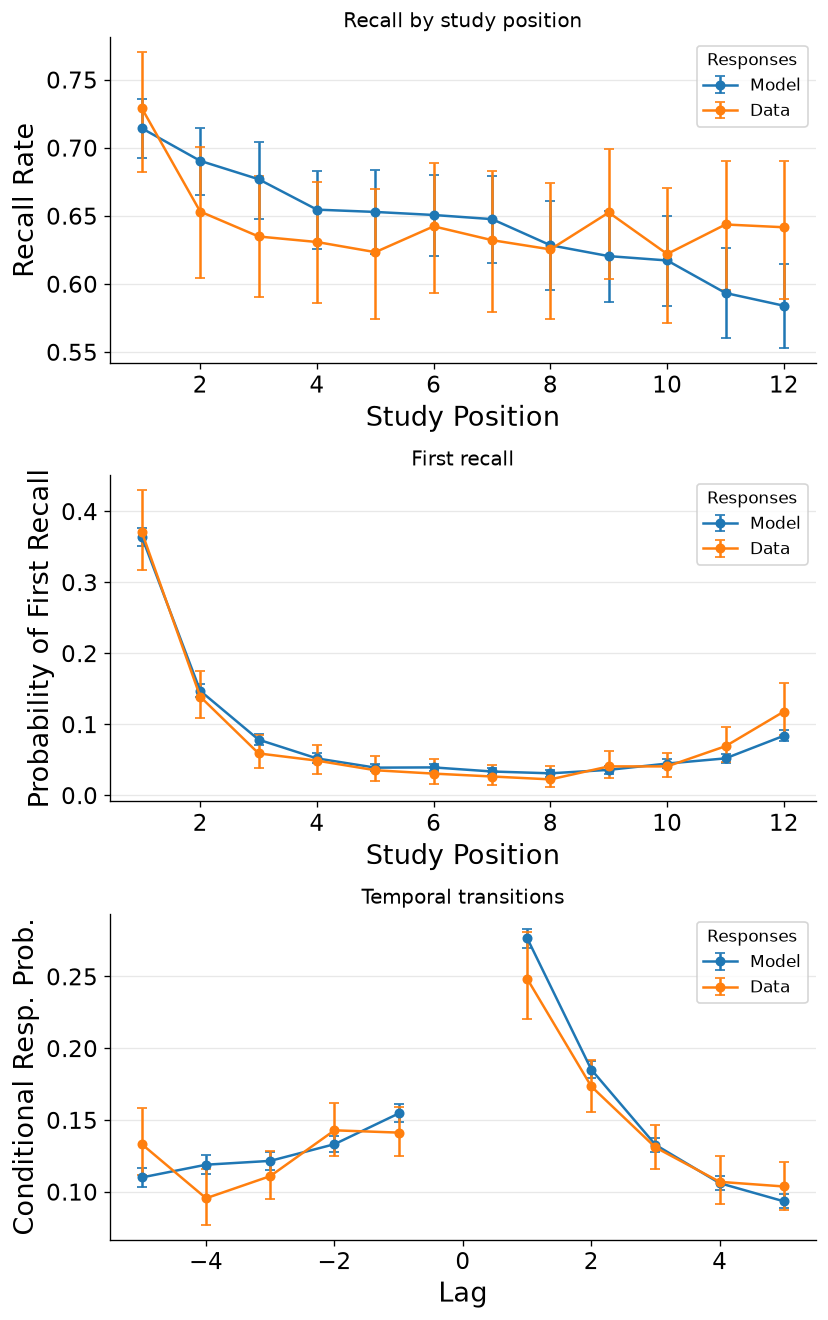

In [9]:
#| code-summary: "Run the configured behavioral comparisons"

if redo_figures and simulated is not None:
    for configs, views, filename in [
        (comparison_analysis_configs, [([simulated, data], ["Model", "Data"])], "model_and_data"),
        (single_analysis_configs, [([simulated], ["Model"]), ([data], ["Data"])], "single_dataset"),
    ]:
        for datasets, view_labels in views:
            if not configs:
                continue
            combined = not figure_str
            if combined:
                fig, axes = plt.subplots(len(configs), 1, figsize=(7, 3.7 * len(configs)), squeeze=False)
            for index, config in enumerate(configs):
                plotter = import_from_string(config["target"])
                query = config.get("trial_query", analysis_trial_query)
                masks = [generate_trial_mask(dataset, query) for dataset in datasets]
                # Observed comparisons use the same work-unit selection as the simulation.
                masks = [mask & trial_mask if dataset is data else mask
                         for dataset, mask in zip(datasets, masks)]
                if combined:
                    ax = axes.ravel()[index]
                else:
                    fig, ax = plt.subplots()
                kwargs = {"datasets": datasets if len(datasets) > 1 else datasets[0],
                          "trial_masks": masks if len(masks) > 1 else masks[0],
                          "labels": config.get("labels", view_labels),
                          "contrast_name": config.get("contrast_name", "Responses"),
                          "confidence_level": confidence_level, "axis": ax}
                if config.get("color_cycle") is not None:
                    kwargs["color_cycle"] = config["color_cycle"]
                # Common options vary across plotters; explicit kwargs must be accepted.
                kwargs = {key: value for key, value in kwargs.items()
                          if key in inspect.signature(plotter).parameters}
                kwargs.update(config.get("kwargs", {}))
                plotter(**kwargs)
                if config.get("ylim") is not None:
                    ax.set_ylim(config["ylim"])
                ax.set_title(config.get("title", plotter.__name__.removeprefix("plot_")))
                if not combined:
                    suffix = config.get("figure_suffix", plotter.__name__.removeprefix("plot_"))
                    dataset_suffix = "_sim" if view_labels == ["Model"] else "_data" if view_labels == ["Data"] else ""
                    save_figure(str(figure_dir), figure_str, suffix=f"{suffix}{dataset_suffix}", dpi=160)
            if combined:
                dataset_suffix = "_sim" if view_labels == ["Model"] else "_data" if view_labels == ["Data"] else ""
                save_figure(str(figure_dir), f"{filename}{dataset_suffix}", dpi=160)

## Interpret and use another specification

The supplied nine-parameter CMR fit has negative log likelihood **7202.029**.
The two three-restart searches differed by 0.085; seed 1 supplied
the retained result. This is evidence about these searches, not proof of a global optimum.

The simulation captures the elevated first-position recall, the first-recall distribution and
forward temporal contiguity. It still overpredicts recall at some early/middle positions and
underpredicts late-list recall: position 12 is about 0.58 in the simulation versus 0.64 observed.
Its lag +1 CRP is about 0.28 versus 0.25 observed. These residuals remain relevant even though
the likelihood improved over the former restricted two-parameter example.

Primacy scale is 0.084, small relative to its very broad
[epsilon, 100] search interval. The preparation record identifies values within 1% of either
bound's interval; this screen does not by itself show that a constraint is active. Parameter
interpretation also requires examining tradeoffs and identifiability.

Change parameters, trial selection, model specification or search settings to address your
question. Use distinct run names for independent jobs and preserve matching model, likelihood
and simulation assumptions. The default outputs are `Dupertuys2026_CMR_demo.json`,
`simulated_recalls.h5`, its settings record and `model_and_data.png` in `results/fitting/`.
The **Simulation** template can read the saved fit; the supplied example also lets you start there.